In [115]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.tree import DecisionTreeClassifier

In [116]:
df = pd.read_csv("../data/male_teams.csv")

C:\Users\advai\AppData\Local\Temp\ipykernel_56616\3064921848.py:1: DtypeWarning: Columns (0: def_style, 1: def_defence_defender_line, 2: off_style, 3: off_build_up_play, 4: off_chance_creation, 5: build_up_play_positioning, 6: chance_creation_positioning) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("../data/male_teams.csv")


In [117]:

df.head()

,team_id,team_url,fifa_version,fifa_update,fifa_update_date,team_name,league_id,league_name,league_level,nationality_id,...,off_corners,off_free_kicks,build_up_play_speed,build_up_play_dribbling,build_up_play_passing,build_up_play_positioning,chance_creation_passing,chance_creation_crossing,chance_creation_shooting,chance_creation_positioning
0,10,/team/10/manchester-city/230009,23,9,2023-01-13,Manchester City,13,Premier League,1.0,14,...,3.0,3.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,73,/team/73/paris-saint-germain/230009,23,9,2023-01-13,Paris Saint Germain,16,Ligue 1,1.0,18,...,3.0,3.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,243,/team/243/real-madrid/230009,23,9,2023-01-13,Real Madrid,53,La Liga,1.0,45,...,3.0,3.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,1337,/team/1337/germany/230009,23,9,2023-01-13,Germany,78,Friendly International,NaN,21,...,3.0,3.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,5,/team/5/chelsea/230009,23,9,2023-01-13,Chelsea,13,Premier League,1.0,14,...,3.0,3.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [118]:
df.shape

(385055, 54)

In [119]:
df.columns

Index(['team_id', 'team_url', 'fifa_version', 'fifa_update',
       'fifa_update_date', 'team_name', 'league_id', 'league_name',
       'league_level', 'nationality_id', 'nationality_name', 'overall',
       'attack', 'midfield', 'defence', 'coach_id', 'home_stadium',
       'rival_team', 'international_prestige', 'domestic_prestige',
       'transfer_budget_eur', 'club_worth_eur', 'starting_xi_average_age',
       'whole_team_average_age', 'captain', 'short_free_kick',
       'long_free_kick', 'left_short_free_kick', 'right_short_free_kick',
       'penalties', 'left_corner', 'right_corner', 'def_style',
       'def_team_width', 'def_team_depth', 'def_defence_pressure',
       'def_defence_aggression', 'def_defence_width',
       'def_defence_defender_line', 'off_style', 'off_build_up_play',
       'off_chance_creation', 'off_team_width', 'off_players_in_box',
       'off_corners', 'off_free_kicks', 'build_up_play_speed',
       'build_up_play_dribbling', 'build_up_play_passing',
    

In [120]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 385055 entries, 0 to 385054
Data columns (total 54 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   team_id                      385055 non-null  int64  
 1   team_url                     385055 non-null  str    
 2   fifa_version                 385055 non-null  int64  
 3   fifa_update                  385055 non-null  int64  
 4   fifa_update_date             385055 non-null  str    
 5   team_name                    385055 non-null  str    
 6   league_id                    385055 non-null  int64  
 7   league_name                  385055 non-null  str    
 8   league_level                 359176 non-null  float64
 9   nationality_id               385055 non-null  int64  
 10  nationality_name             385055 non-null  str    
 11  overall                      385055 non-null  int64  
 12  attack                       385055 non-null  int64  
 13  midfield  

In [121]:
df.isnull().sum()

team_id                             0
team_url                            0
fifa_version                        0
fifa_update                         0
fifa_update_date                    0
team_name                           0
league_id                           0
league_name                         0
league_level                    25879
nationality_id                      0
nationality_name                    0
overall                             0
attack                              0
midfield                            0
defence                             0
coach_id                         2328
home_stadium                      288
rival_team                          0
international_prestige              0
domestic_prestige               25829
transfer_budget_eur             31922
club_worth_eur                  94962
starting_xi_average_age             0
whole_team_average_age              0
captain                           444
short_free_kick                   478
long_free_ki

In [122]:
columns = [
    "team_name",
    "overall",
    "attack",
    "midfield",
    "defence",
    "starting_xi_average_age",
    "whole_team_average_age",
    "international_prestige",
    "domestic_prestige"
]

df = df[columns]

In [123]:
df.head()

,team_name,overall,attack,midfield,defence,starting_xi_average_age,whole_team_average_age,international_prestige,domestic_prestige
0,Manchester City,85,85,86,86,27.09,25.88,10,10.0
1,Paris Saint Germain,85,87,83,83,26.82,26.04,9,10.0
2,Real Madrid,85,85,86,84,28.55,24.64,10,10.0
3,Germany,85,82,85,82,28.27,27.22,10,NaN
4,Chelsea,84,83,83,83,26.73,24.55,8,9.0


In [124]:
df.isnull().sum()

team_name                      0
overall                        0
attack                         0
midfield                       0
defence                        0
starting_xi_average_age        0
whole_team_average_age         0
international_prestige         0
domestic_prestige          25829
dtype: int64

In [125]:
df.duplicated().sum()

np.int64(277459)

In [126]:
df = df.drop_duplicates()

In [127]:
df.shape

(107596, 9)

In [128]:
df.duplicated().sum()

np.int64(0)

In [129]:
df.isnull().sum()

team_name                     0
overall                       0
attack                        0
midfield                      0
defence                       0
starting_xi_average_age       0
whole_team_average_age        0
international_prestige        0
domestic_prestige          3965
dtype: int64

In [130]:
df = df.dropna()

In [131]:
df.shape

(103631, 9)

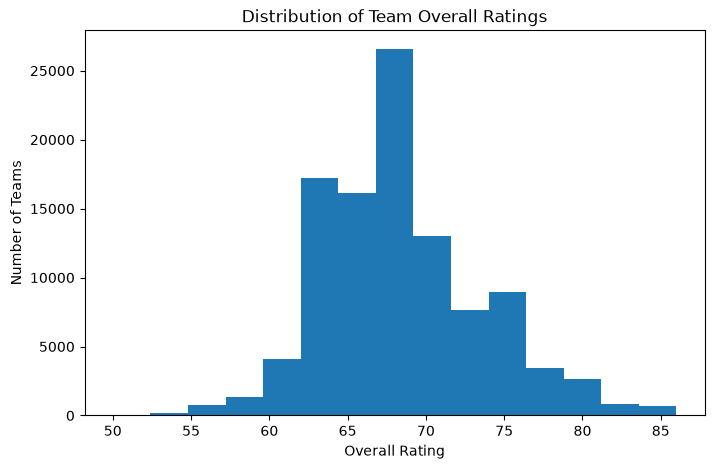

In [132]:
plt.figure(figsize=(8,5))
plt.hist(df["overall"], bins=15)
plt.title("Distribution of Team Overall Ratings")
plt.xlabel("Overall Rating")
plt.ylabel("Number of Teams")
plt.savefig("../images/overallRatings.png", dpi=300, bbox_inches="tight")
plt.show()

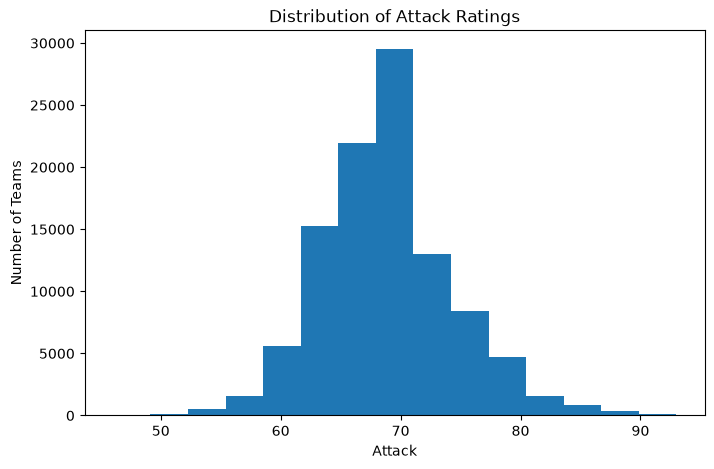

In [133]:
plt.figure(figsize=(8,5))
plt.hist(df["attack"], bins=15)
plt.title("Distribution of Attack Ratings")
plt.xlabel("Attack")
plt.ylabel("Number of Teams")
plt.savefig("../images/attackRatings.png", dpi=300, bbox_inches="tight")
plt.show()

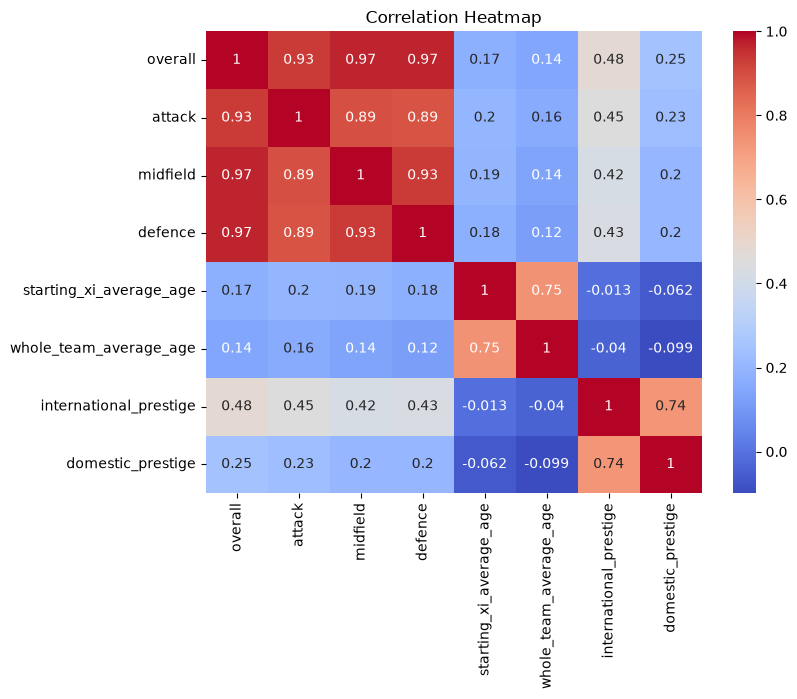

In [134]:
plt.figure(figsize=(8,6))

sns.heatmap(df.corr(numeric_only=True),
            annot=True,
            cmap="coolwarm")

plt.title("Correlation Heatmap")
plt.savefig("../images/CorrelationHeatmap.png", dpi=300, bbox_inches="tight")
plt.show()

In [135]:
top10 = df.sort_values("overall", ascending=False)

top10[["team_name", "overall"]].head(10)

,team_name,overall
227668,FC Bayern München,86
203970,FC Bayern München,86
44722,Paris Saint Germain,86
127439,Real Madrid CF,86
126721,FC Barcelona,86
126722,Real Madrid CF,86
128155,FC Barcelona,86
125287,FC Barcelona,86
125288,Real Madrid CF,86
52062,Paris Saint Germain,86


In [136]:
df.describe()

,overall,attack,midfield,defence,starting_xi_average_age,whole_team_average_age,international_prestige,domestic_prestige
count,103631.000000,103631.000000,103631.000000,103631.000000,103631.00000,103631.000000,103631.000000,103631.000000
mean,68.363800,68.786319,68.051519,67.542482,26.19792,24.754453,4.202796,7.477251
std,5.131882,5.634789,5.358195,5.207995,1.68081,1.354170,3.845052,4.575248
min,50.000000,46.000000,48.000000,48.000000,18.82000,19.000000,1.000000,1.000000
25%,65.000000,65.000000,64.000000,64.000000,25.09000,23.880000,1.000000,4.000000
50%,68.000000,68.000000,68.000000,67.000000,26.18000,24.740000,3.000000,7.000000
75%,71.000000,72.000000,71.000000,71.000000,27.36000,25.640000,6.000000,10.000000
max,86.000000,93.000000,89.000000,87.000000,33.00000,33.110000,20.000000,20.000000


In [137]:
def performance_tier(overall):
    if overall >= 85:
        return "Elite"
    elif overall >= 80:
        return "Good"
    elif overall >= 75:
        return "Average"
    else:
        return "Weak"

df["performance_tier"] = df["overall"].apply(performance_tier)

In [138]:
df[["team_name", "overall", "performance_tier"]].head(10)

,team_name,overall,performance_tier
0,Manchester City,85,Elite
1,Paris Saint Germain,85,Elite
2,Real Madrid,85,Elite
4,Chelsea,84,Good
5,Liverpool,84,Good
6,FC Bayern München,84,Good
7,FC Barcelona,84,Good
9,Inter,83,Good
15,Manchester United,82,Good
16,Juventus,82,Good


In [139]:
df["performance_tier"].value_counts()

performance_tier
Weak       90268
Average    10503
Good        2473
Elite        387
Name: count, dtype: int64

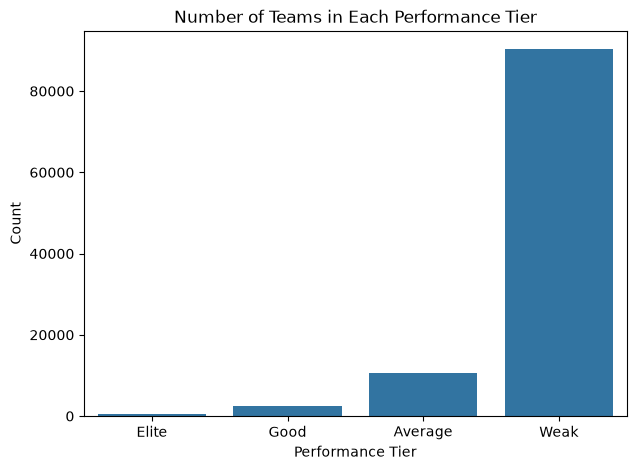

In [140]:
plt.figure(figsize=(7,5))

sns.countplot(data=df, x="performance_tier")

plt.title("Number of Teams in Each Performance Tier")
plt.xlabel("Performance Tier")
plt.ylabel("Count")
plt.savefig("../images/PerformanceTier.png", dpi=300, bbox_inches="tight")
plt.show()

In [141]:
features = [
    "attack",
    "midfield",
    "defence",
    "starting_xi_average_age",
    "whole_team_average_age",
    "international_prestige",
    "domestic_prestige"
]

X = df[features]
y = df["performance_tier"]

In [142]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [143]:
model = RandomForestClassifier(random_state=42)

In [144]:
model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

In [145]:
y_pred = model.predict(X_test)

In [146]:
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)

Accuracy: 0.9924253389298981


In [147]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

     Average       0.97      0.96      0.96      2068
       Elite       0.98      0.96      0.97        92
        Good       0.97      0.97      0.97       499
        Weak       1.00      1.00      1.00     18068

    accuracy                           0.99     20727
   macro avg       0.98      0.97      0.97     20727
weighted avg       0.99      0.99      0.99     20727



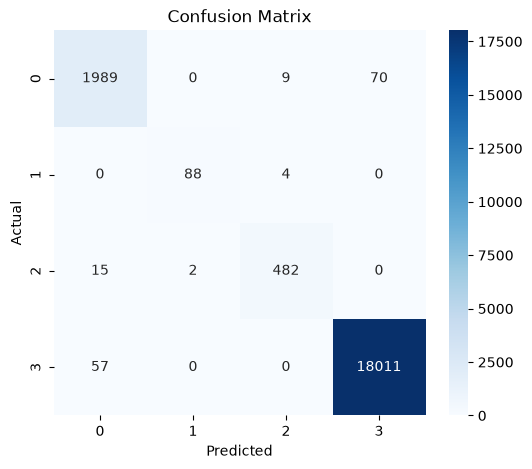

In [148]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6,5))

sns.heatmap(cm,
            annot=True,
            fmt="d",
            cmap="Blues")

plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.savefig("../images/ConfusionMatrix.png", dpi=300, bbox_inches="tight")
plt.show()

In [149]:
dt_model = DecisionTreeClassifier(random_state=42)

dt_model.fit(X_train, y_train)

dt_pred = dt_model.predict(X_test)

In [150]:
dt_accuracy = accuracy_score(y_test, dt_pred)

print("Decision Tree Accuracy:", dt_accuracy)

Decision Tree Accuracy: 0.9873112365513581


In [151]:
comparison = pd.DataFrame({
    "Model": ["Random Forest", "Decision Tree"],
    "Accuracy": [accuracy, dt_accuracy]
})

comparison

,Model,Accuracy
0,Random Forest,0.992425
1,Decision Tree,0.987311


In [152]:
import joblib

joblib.dump(model, "../model.pkl")

['../model.pkl']

In [153]:
comparison = pd.DataFrame({
    "Model": ["Random Forest", "Decision Tree"],
    "Accuracy": [accuracy, dt_accuracy]
})

comparison

,Model,Accuracy
0,Random Forest,0.992425
1,Decision Tree,0.987311
